# 01 · Theory Validation

**A Variational Control Framework for Optimal Portfolio Rebalancing Under Transaction Costs**

This notebook validates the building blocks of the model before we solve any control problem:

1. the discrete-time geometric-Brownian-motion return model and its Gauss–Hermite quadrature;
2. the CRRA utility and the frictionless **Merton fraction** $w^\* = (\mu-r)/(\gamma\sigma^2)$;
3. the homogeneity property that lets us reduce the state space.

In [1]:
import os, sys
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt


In [2]:
from src.config import Config
from src import dynamics
cfg = Config()
print('Annualized parameters:')
print(f'  mu={cfg.mu}, sigma={cfg.sigma}, r={cfg.r}, gamma={cfg.gamma}, tc={cfg.tc}')
print(f'  horizon T={cfg.T}y over n_steps={cfg.n_steps} (dt={cfg.dt:.5f})')
print(f'  Merton fraction w* = {cfg.merton_fraction:.4f}')

Annualized parameters:
  mu=0.08, sigma=0.2, r=0.02, gamma=5.0, tc=0.01
  horizon T=1.0y over n_steps=52 (dt=0.01923)
  Merton fraction w* = 0.3000


## 1. Return model and quadrature

Over one step the risky gross return is $R=\exp\big((\mu-\tfrac12\sigma^2)\,dt+\sigma\sqrt{dt}\,Z\big)$, $Z\sim N(0,1)$, and the risk-free gross return is $R_f=e^{r\,dt}$.

We evaluate conditional expectations with Gauss–Hermite quadrature. The quadrature moments should match the closed-form lognormal moments $E[R]=e^{\mu dt}$ and $E[R^2]=e^{2\mu dt+\sigma^2 dt}$.

In [3]:
R, p = dynamics.gross_return_quadrature(cfg)
Rf = dynamics.risk_free_gross(cfg)
ER_quad, ER2_quad = np.sum(p*R), np.sum(p*R**2)
ER_exact = np.exp(cfg.mu*cfg.dt)
ER2_exact = np.exp(2*cfg.mu*cfg.dt + cfg.sigma**2*cfg.dt)
print(f'Risk-free gross R_f = {Rf:.6f}')
print(f'E[R]:  quadrature={ER_quad:.8f}  exact={ER_exact:.8f}  err={abs(ER_quad-ER_exact):.2e}')
print(f'E[R^2]:quadrature={ER2_quad:.8f}  exact={ER2_exact:.8f}  err={abs(ER2_quad-ER2_exact):.2e}')
print(f'weights sum = {p.sum():.8f}, # nodes = {cfg.n_quad}')

Risk-free gross R_f = 1.000385
E[R]:  quadrature=1.00153965  exact=1.00153965  err=2.22e-16
E[R^2]:quadrature=1.00385356  exact=1.00385356  err=0.00e+00
weights sum = 1.00000000, # nodes = 21


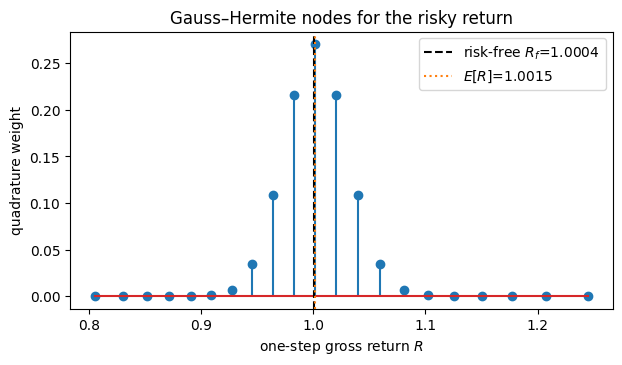

In [4]:
# Visualize the one-step gross-return distribution sampled by the quadrature.
fig, ax = plt.subplots(figsize=(7,3.6))
ax.stem(R, p)
ax.axvline(Rf, color='k', ls='--', label=f'risk-free $R_f$={Rf:.4f}')
ax.axvline(ER_quad, color='C1', ls=':', label=f'$E[R]$={ER_quad:.4f}')
ax.set_xlabel('one-step gross return $R$'); ax.set_ylabel('quadrature weight')
ax.set_title('Gauss–Hermite nodes for the risky return'); ax.legend(); plt.show()

## 2. CRRA utility and the Merton fraction

Preferences are $U(W)=W^{1-\gamma}/(1-\gamma)$. In the frictionless, continuous-time limit the optimal constant risky weight is the **Merton fraction** $w^\*=(\mu-r)/(\gamma\sigma^2)$, which will be the centre of the no-trade region.

In [5]:
import numpy as np
for g in [2,3,5,8,12]:
    w = (cfg.mu-cfg.r)/(g*cfg.sigma**2)
    print(f'gamma={g:2d}  ->  Merton fraction w* = {w:.4f}')

gamma= 2  ->  Merton fraction w* = 0.7500
gamma= 3  ->  Merton fraction w* = 0.5000
gamma= 5  ->  Merton fraction w* = 0.3000
gamma= 8  ->  Merton fraction w* = 0.1875
gamma=12  ->  Merton fraction w* = 0.1250


## 3. Homogeneity ⇒ dimensionality reduction

Because $U$ is homogeneous of degree $1-\gamma$ and transaction costs are proportional, scaling wealth by $\kappa$ scales every dollar trade and the next wealth by $\kappa$ while leaving all *fractions* unchanged. Hence
$$V_t(\kappa W, x)=\kappa^{1-\gamma}V_t(W,x)\ \Rightarrow\ V_t(W,x)=W^{1-\gamma}g_t(x).$$
The whole problem collapses to a 1-D function $g_t(x)$ of the risky fraction. We verify the multiplier identity that makes this work.

In [6]:
from src.transaction_costs import wealth_multiplier, trade_fraction
tc = cfg.tc
print('Check: post-trade fraction is recovered exactly for any (x,y).')
for (x,y) in [(0.30,0.30),(0.10,0.50),(0.80,0.30)]:
    m = wealth_multiplier(x,y,tc); d = trade_fraction(x,y,tc)
    rec = (x+d)/m
    tag = 'no trade' if abs(y-x)<1e-12 else ('buy' if d>0 else 'sell')
    print(f'  x={x:.2f} y={y:.2f} [{tag:8s}]  m={m:.5f}  delta={d:+.5f}  recovered_y={rec:.5f}')

Check: post-trade fraction is recovered exactly for any (x,y).
  x=0.30 y=0.30 [no trade]  m=1.00000  delta=+0.00000  recovered_y=0.30000
  x=0.10 y=0.50 [buy     ]  m=0.99602  delta=+0.39801  recovered_y=0.50000
  x=0.80 y=0.30 [sell    ]  m=0.99498  delta=-0.50150  recovered_y=0.30000


**Takeaways.** The quadrature reproduces the lognormal moments to machine precision; the Merton fraction is $0.30$ for our base case ($\gamma=5$); and the proportional-cost bookkeeping is internally consistent. We can now solve the control problem in one dimension — see **02_dynamic_programming**.